# LAB 3:   Text to Latent Representation using Word Embeddings and Flatten Vector Extraction 

In [67]:
pip install numpy pandas matplotlib scikit-learn tensorflow


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [68]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding

from sklearn.decomposition import PCA

### 1. Pre-process the given text dataset and create a vocabulary containing all unique words present in the dataset.

In [69]:
# Given text dataset
texts = [
    "The product quality is excellent",
    "I really love this product",
    "The quality of this item is amazing",
    "The product performance is poor",
    "I dislike this product completely"
]

# Convert all text to lowercase as part of preprocessing
texts_cleaned = [text.lower() for text in texts]

# Create a tokenizer
tokenizer = Tokenizer()

# Learn the vocabulary from the dataset
tokenizer.fit_on_texts(texts_cleaned)

# Extract the vocabulary
word_index = tokenizer.word_index

print("Vocabulary with Unique Words:")
print("-" * 40)

for word, token_id in word_index.items():
    print(word, ":", token_id)

Vocabulary with Unique Words:
----------------------------------------
product : 1
the : 2
is : 3
this : 4
quality : 5
i : 6
excellent : 7
really : 8
love : 9
of : 10
item : 11
amazing : 12
performance : 13
poor : 14
dislike : 15
completely : 16


### Assign a unique numerical identifier (token ID) to each word in the vocabulary.

In [70]:
print("Word to Token ID Mapping:")
print("-" * 40)

for word, token_id in word_index.items():
    print(f"{word:15} -> {token_id}")

Word to Token ID Mapping:
----------------------------------------
product         -> 1
the             -> 2
is              -> 3
this            -> 4
quality         -> 5
i               -> 6
excellent       -> 7
really          -> 8
love            -> 9
of              -> 10
item            -> 11
amazing         -> 12
performance     -> 13
poor            -> 14
dislike         -> 15
completely      -> 16


### Convert each text sentence into a sequence of token IDs using the generated vocabulary.

In [71]:
sequences = tokenizer.texts_to_sequences(texts_cleaned)

print("Token ID Sequences:")
print("-" * 40)

for i, sequence in enumerate(sequences, start=1):
    print(f"Sentence {i}: {sequence}")

Token ID Sequences:
----------------------------------------
Sentence 1: [2, 1, 5, 3, 7]
Sentence 2: [6, 8, 9, 4, 1]
Sentence 3: [2, 5, 10, 4, 11, 3, 12]
Sentence 4: [2, 1, 13, 3, 14]
Sentence 5: [6, 15, 4, 1, 16]


### Apply padding to the token sequences so that all text samples have the same length and can be represented in a uniform format.

In [72]:
# Find the maximum sequence length
max_length = max(len(sequence) for sequence in sequences)

print("Maximum Sequence Length:", max_length)

# Apply post-padding with zeros
padded_sequences = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post"
)

print("\nPadded Token Sequences:")
print("-" * 40)

for i, sequence in enumerate(padded_sequences, start=1):
    print(f"Sentence {i}: {sequence}")

Maximum Sequence Length: 7

Padded Token Sequences:
----------------------------------------
Sentence 1: [2 1 5 3 7 0 0]
Sentence 2: [6 8 9 4 1 0 0]
Sentence 3: [ 2  5 10  4 11  3 12]
Sentence 4: [ 2  1 13  3 14  0  0]
Sentence 5: [ 6 15  4  1 16  0  0]


### Generate word embeddings for each token using an embedding representation. Every word is converted from a token ID into a dense numerical vector of fixed dimensions.

In [73]:
# Number of unique words + 1 for the padding token
vocab_size = len(word_index) + 1

# Number of dimensions for each word embedding
embedding_dim = 5

# Create an embedding model
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    )
])

# Generate embeddings for the padded sequences
embedding_matrix = model(padded_sequences)

# Convert TensorFlow tensor to NumPy array
embedding_matrix = embedding_matrix.numpy()

print("Embedding Matrix Shape:")
print(embedding_matrix.shape)

Embedding Matrix Shape:
(5, 7, 5)


### Display the word embedding representation of the given sentencesand observe how each word is represented as a multidimensional vector.


In [74]:
# Obtain the weights of the embedding layer
embedding_weights = model.layers[0].get_weights()[0]

print("Word Embedding Representations:")
print("=" * 60)

for word, token_id in word_index.items():

    # Get the embedding vector corresponding to the token ID
    vector = embedding_weights[token_id]

    print(f"\nWord       : {word}")
    print(f"Token ID   : {token_id}")
    print("Embedding  :", np.round(vector, 4))

Word Embedding Representations:

Word       : product
Token ID   : 1
Embedding  : [-0.0392 -0.0034 -0.0167 -0.0498  0.0115]

Word       : the
Token ID   : 2
Embedding  : [-0.0112 -0.0123  0.0187 -0.0179 -0.0289]

Word       : is
Token ID   : 3
Embedding  : [-0.0337 -0.0199 -0.0485  0.0434  0.0192]

Word       : this
Token ID   : 4
Embedding  : [ 0.0155  0.0451  0.0268  0.013  -0.0438]

Word       : quality
Token ID   : 5
Embedding  : [0.0438 0.0102 0.0247 0.0043 0.0404]

Word       : i
Token ID   : 6
Embedding  : [-0.0085  0.03    0.0421 -0.0154 -0.0212]

Word       : excellent
Token ID   : 7
Embedding  : [-0.0147  0.0282 -0.0199 -0.0456 -0.0232]

Word       : really
Token ID   : 8
Embedding  : [ 0.0294  0.0239  0.0247  0.0301 -0.0493]

Word       : love
Token ID   : 9
Embedding  : [-0.0228 -0.0416  0.023  -0.0484  0.0254]

Word       : of
Token ID   : 10
Embedding  : [ 0.0256  0.0489  0.0255  0.0166 -0.007 ]

Word       : item
Token ID   : 11
Embedding  : [-0.0252  0.0369 -0.0166  0.0

### Display the complete word embedding matrix for each sentence.

In [75]:
for i, matrix in enumerate(embedding_matrix, start=1):

    print("\n" + "=" * 60)
    print(f"Sentence {i}: {texts[i - 1]}")
    print("=" * 60)

    print("Embedding Matrix:")
    print(np.round(matrix, 4))


Sentence 1: The product quality is excellent
Embedding Matrix:
[[-0.0112 -0.0123  0.0187 -0.0179 -0.0289]
 [-0.0392 -0.0034 -0.0167 -0.0498  0.0115]
 [ 0.0438  0.0102  0.0247  0.0043  0.0404]
 [-0.0337 -0.0199 -0.0485  0.0434  0.0192]
 [-0.0147  0.0282 -0.0199 -0.0456 -0.0232]
 [-0.0106  0.0193  0.0163  0.0059 -0.0485]
 [-0.0106  0.0193  0.0163  0.0059 -0.0485]]

Sentence 2: I really love this product
Embedding Matrix:
[[-0.0085  0.03    0.0421 -0.0154 -0.0212]
 [ 0.0294  0.0239  0.0247  0.0301 -0.0493]
 [-0.0228 -0.0416  0.023  -0.0484  0.0254]
 [ 0.0155  0.0451  0.0268  0.013  -0.0438]
 [-0.0392 -0.0034 -0.0167 -0.0498  0.0115]
 [-0.0106  0.0193  0.0163  0.0059 -0.0485]
 [-0.0106  0.0193  0.0163  0.0059 -0.0485]]

Sentence 3: The quality of this item is amazing
Embedding Matrix:
[[-0.0112 -0.0123  0.0187 -0.0179 -0.0289]
 [ 0.0438  0.0102  0.0247  0.0043  0.0404]
 [ 0.0256  0.0489  0.0255  0.0166 -0.007 ]
 [ 0.0155  0.0451  0.0268  0.013  -0.0438]
 [-0.0252  0.0369 -0.0166  0.0039 -

### Convert the word embedding matrix of each sentence into a single flattened vector representation.

In [76]:
# Flatten the embedding matrix of every sentence
flattened_vectors = embedding_matrix.reshape(
    embedding_matrix.shape[0],
    -1
)

print("Flattened Vector Representations:")
print("=" * 70)

for i, vector in enumerate(flattened_vectors, start=1):

    print(f"\nSentence {i}:")
    print(texts[i - 1])

    print("\nFlattened Vector:")
    print(np.round(vector, 4))

print("\nShape of flattened vectors:")
print(flattened_vectors.shape)

Flattened Vector Representations:

Sentence 1:
The product quality is excellent

Flattened Vector:
[-0.0112 -0.0123  0.0187 -0.0179 -0.0289 -0.0392 -0.0034 -0.0167 -0.0498
  0.0115  0.0438  0.0102  0.0247  0.0043  0.0404 -0.0337 -0.0199 -0.0485
  0.0434  0.0192 -0.0147  0.0282 -0.0199 -0.0456 -0.0232 -0.0106  0.0193
  0.0163  0.0059 -0.0485 -0.0106  0.0193  0.0163  0.0059 -0.0485]

Sentence 2:
I really love this product

Flattened Vector:
[-0.0085  0.03    0.0421 -0.0154 -0.0212  0.0294  0.0239  0.0247  0.0301
 -0.0493 -0.0228 -0.0416  0.023  -0.0484  0.0254  0.0155  0.0451  0.0268
  0.013  -0.0438 -0.0392 -0.0034 -0.0167 -0.0498  0.0115 -0.0106  0.0193
  0.0163  0.0059 -0.0485 -0.0106  0.0193  0.0163  0.0059 -0.0485]

Sentence 3:
The quality of this item is amazing

Flattened Vector:
[-0.0112 -0.0123  0.0187 -0.0179 -0.0289  0.0438  0.0102  0.0247  0.0043
  0.0404  0.0256  0.0489  0.0255  0.0166 -0.007   0.0155  0.0451  0.0268
  0.013  -0.0438 -0.0252  0.0369 -0.0166  0.0039 -0.0021 -

### Visualize the generated word embeddings by reducing their dimensions using PCA and observe the relative positioning of different words in the embedding space.

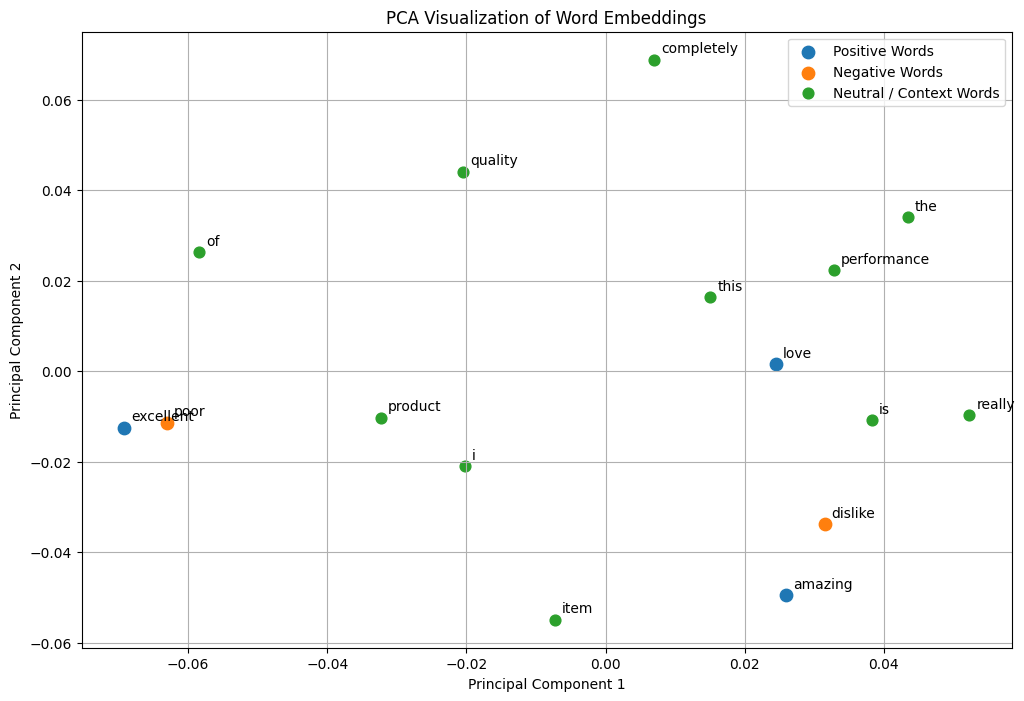

In [77]:
positive_words = {
    "excellent",
    "love",
    "amazing"
}

negative_words = {
    "poor",
    "dislike"
}

neutral_words = set(words) - positive_words - negative_words


# Create the PCA plot
plt.figure(figsize=(12, 8))


# Plot positive words
positive_indices = [
    i for i, word in enumerate(words)
    if word in positive_words
]

plt.scatter(
    word_vectors_2d[positive_indices, 0],
    word_vectors_2d[positive_indices, 1],
    label="Positive Words",
    s=80
)


# Plot negative words
negative_indices = [
    i for i, word in enumerate(words)
    if word in negative_words
]

plt.scatter(
    word_vectors_2d[negative_indices, 0],
    word_vectors_2d[negative_indices, 1],
    label="Negative Words",
    s=80
)


# Plot neutral/context words
neutral_indices = [
    i for i, word in enumerate(words)
    if word in neutral_words
]

plt.scatter(
    word_vectors_2d[neutral_indices, 0],
    word_vectors_2d[neutral_indices, 1],
    label="Neutral / Context Words",
    s=60
)


# Add word labels
for i, word in enumerate(words):

    plt.annotate(
        word,
        (
            word_vectors_2d[i, 0],
            word_vectors_2d[i, 1]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=10
    )


# Graph details
plt.title("PCA Visualization of Word Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)

plt.show()

## INFERENCE: 
The PCA plot reduces the word embeddings to two dimensions and categorizes them as positive, negative, and neutral/context words. Positive words such as excellent, love, and amazing and negative words such as poor and dislike appear at different positions, but there is no clear sentiment-based separation. For example, excellent and poor are located close together despite having opposite meanings. This shows that the embeddings capture numerical representations of the words, but the current embedding space has not learned a strong sentiment structure.

### Final output Verification

In [78]:
print("=" * 60)
print("FINAL OUTPUT VERIFICATION")
print("=" * 60)

print("Number of sentences       :", len(texts))
print("Vocabulary size           :", len(word_index))
print("Maximum sequence length   :", max_length)
print("Embedding dimension       :", embedding_dim)
print("Padded sequences shape    :", padded_sequences.shape)
print("Embedding matrix shape    :", embedding_matrix.shape)
print("Flattened vectors shape   :", flattened_vectors.shape)

FINAL OUTPUT VERIFICATION
Number of sentences       : 5
Vocabulary size           : 16
Maximum sequence length   : 7
Embedding dimension       : 5
Padded sequences shape    : (5, 7)
Embedding matrix shape    : (5, 7, 5)
Flattened vectors shape   : (5, 35)


### CONCLUSION:
The final output confirms that the text data has been successfully converted into numerical latent representations. The 5 sentences were tokenized using a vocabulary of 16 indices, including the padding index. After padding, each sentence is represented by 7 tokens. Each token is then converted into a 5-dimensional embedding vector, producing an embedding representation of shape (5, 7, 5). Finally, flattening converts each sentence into a 35-dimensional vector (7 × 5), giving a final representation of (5, 35) for the complete dataset.

## SELF LEARNING - Automatic Word Clustering

In [79]:
from sklearn.cluster import KMeans


# Number of clusters to discover
num_clusters = 3


# Create the K-Means model
kmeans = KMeans(
    n_clusters=num_clusters,
    random_state=42,
    n_init=10
)


# Train K-Means using the word embedding vectors
cluster_labels = kmeans.fit_predict(word_vectors)


# Display the automatically discovered clusters
print("Automatically Discovered Word Clusters")
print("=" * 50)

for cluster in range(num_clusters):

    cluster_words = [
        word
        for word, label in zip(words, cluster_labels)
        if label == cluster
    ]

    print(f"\nCluster {cluster + 1}:")
    print(cluster_words)

Automatically Discovered Word Clusters

Cluster 1:
['is', 'really', 'love', 'amazing', 'dislike']

Cluster 2:
['product', 'i', 'excellent', 'of', 'item', 'poor']

Cluster 3:
['the', 'this', 'quality', 'performance', 'completely']


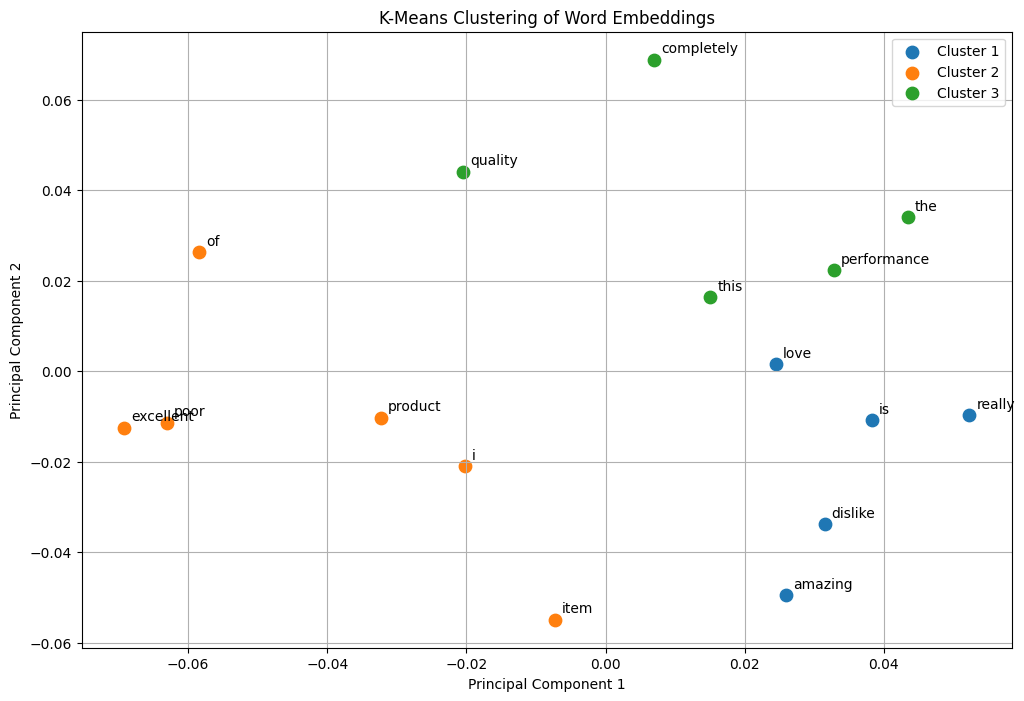

In [80]:
# Visualize the automatically discovered word clusters

plt.figure(figsize=(12, 8))

# Plot each automatically discovered cluster
for cluster in range(num_clusters):

    cluster_indices = [
        i
        for i, label in enumerate(cluster_labels)
        if label == cluster
    ]

    plt.scatter(
        word_vectors_2d[cluster_indices, 0],
        word_vectors_2d[cluster_indices, 1],
        label=f"Cluster {cluster + 1}",
        s=80
    )


# Add word labels
for i, word in enumerate(words):

    plt.annotate(
        word,
        (
            word_vectors_2d[i, 0],
            word_vectors_2d[i, 1]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=10
    )


plt.title("K-Means Clustering of Word Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)

plt.show()

## INFERENCE:
The K-Means plot automatically divides the word embeddings into three clusters based on their numerical similarity, without using positive or negative labels. The resulting clusters do not exactly match the manually assigned sentiment categories; positive, negative, and neutral words can occur in the same cluster. This demonstrates the self-learning/unsupervised nature of K-Means, where groups are discovered from patterns in the embedding vectors rather than predefined sentiment information.